# Angle Ranges: How To Ask About An Azimuth

**Version**: 1

**Last modified**: 2026-10-12

**Compatible with opengate-gate-tree version:** 0.6.0

**Author**: Mateusz Jakub Bała

## About

An angle is only defined up to whole turns: the same direction is π/2 and
−3π/2, and a calculation that answers one has answered the other. Which of
them a histogram or a comparison wants is part of the question being asked.
This notebook asks one question three ways — how far apart, around the axis,
are the two gammas of an annihilation — and shows that the range an angle is
read into decides whether the answer reads as one peak, as two halves, or as
no difference at all.

## What will you learn from this notebook

- how to read angles into any range, and into the two everyday ones
- why a range a full turn wide only changes how a direction is written, and a
  narrower one changes what counts as the same direction
- how to choose the range so that a histogram does not cut its own peak in two
- why the ranges are half-open, and what that protects against

## Theory

An angle $\theta$ is read into the range $[\theta_{\min}, \theta_{\max})$ by
removing whole widths of the range:

$$
\theta' = \theta_{\min} +
          \left(\theta - \theta_{\min}\right) \bmod
          \left(\theta_{\max} - \theta_{\min}\right)
$$

When the width is a full turn, $2\pi$, the result describes the same direction
as $\theta$, written differently. When it is narrower, angles that differ by
the width are read as one: in $[0, \pi)$ a direction and its reverse,
$\theta$ and $\theta + \pi$, give the same answer — which is what an undirected
line means.

The two everyday ranges are $[0, 2\pi)$, where an azimuth is binned, and
$[-\pi, \pi)$, where a difference of two angles is read as the shorter turn.

## Tutorial

Every step below is a line of text, the code that does what the line says, and
a word about the answer where the answer needs one.

In [1]:
from tools import environment, paths, plotting

plotting.use_tutorial_style()
print(environment.describe())

opengate-gate-tree: 0.5.0
python: 3.14.5
run on: 2026-10-12


The header of this notebook states the version it was written for; the line
above states the version it just ran against. If they differ, the notebook may
still be right — but nobody has checked it against what is installed.

The example file this notebook reads is a small GATE output carried in the
repository; what it holds is described in
[`../data/README.md`](../data/README.md). Nothing is written, so no output
directory is needed.

In [2]:
import numpy as np
import pandas as pd

from opengate_gate_tree import (
    GammaType,
    GateTree,
    SourceType,
    read_tree,
    transform_to_angle_range,
    wrap_to_signed_pi,
    wrap_to_two_pi,
)

example_input = paths.input_example("positronium-source-all-variants.root")
frame = read_tree(example_input, GateTree.HITS).to_dataframe()

### One Direction, Many Ways Of Writing It

Four angles, written in units of π: −3π/2, −π/2, π/2 and 3π/2. Read into five
ranges, each a row:

In [3]:
angles = np.array([-1.5, -0.5, 0.5, 1.5]) * np.pi
ranges = {
    "[0, 2π)": (0.0, 2.0 * np.pi),
    "[-π, π)": (-np.pi, np.pi),
    "[0, π)": (0.0, np.pi),
    "[-π/2, π/2)": (-np.pi / 2, np.pi / 2),
    "[0, π/2)": (0.0, np.pi / 2),
}

pd.DataFrame(
    {
        name: transform_to_angle_range(angles, low, high) / np.pi
        for name, (low, high) in ranges.items()
    },
    index=["-3π/2", "-π/2", "π/2", "3π/2"],
).T

,-3π/2,-π/2,π/2,3π/2
"[0, 2π)",0.5,1.5,0.5,1.5
"[-π, π)",0.5,-0.5,0.5,-0.5
"[0, π)",0.5,0.5,0.5,0.5
"[-π/2, π/2)",-0.5,-0.5,-0.5,-0.5
"[0, π/2)",0.0,0.0,0.0,0.0


The two ranges a full turn wide keep two answers: −3π/2 and π/2 are one
direction, −π/2 and 3π/2 the other, written as `0.5` and `1.5` in `[0, 2π)`
and as `0.5` and `-0.5` in `[-π, π)`. The ranges half a turn wide fold those
two into one, because −π/2 and π/2 are a direction and its reverse. A quarter
turn folds even more: everything here is read as `0`. Choosing a range is
choosing what counts as the same.

`wrap_to_two_pi` and `wrap_to_signed_pi` are the first two rows, under names
that say which:

In [4]:
wrap_to_two_pi(angles) / np.pi, wrap_to_signed_pi(angles) / np.pi

(array([0.5, 1.5, 0.5, 1.5]), array([ 0.5, -0.5,  0.5, -0.5]))

### The Two Gammas Of An Annihilation

A decay into two gammas sends them back to back. This file holds three such
sources — the back-to-back source, para-positronium and direct annihilation —
and a fourth, ortho-positronium, which decays into three. The first hit of each
track is where the gamma first deposited energy; the source sits at the origin,
so the position of that hit is the direction the gamma left in.

In [5]:
frame["hitIndex"] = frame.groupby(["runID", "eventID", "trackID"]).cumcount()
first = frame[frame["hitIndex"] == 0]

two_gamma_sources = [
    SourceType.NOT_DEFINED,
    SourceType.PARA_POSITRONIUM,
    SourceType.DIRECT_ANNIHILATION,
]
pair_hits = first[
    first["sourceType"].isin(two_gamma_sources) & (first["gammaType"] != GammaType.PROMPT)
]

A prompt gamma, where there is one, is left out: it is emitted on its own and
is not part of the pair. Only the events where both gammas were detected make a
pair, and the two hits of a pair are put on one row:

In [6]:
event = ["runID", "eventID"]
pair_hits = pair_hits[pair_hits.groupby(event)["trackID"].transform("size") == 2]
pair_hits = pair_hits.assign(member=pair_hits.groupby(event).cumcount())

pairs = pair_hits[pair_hits["member"] == 0].merge(
    pair_hits[pair_hits["member"] == 1], on=event, suffixes=("_1", "_2")
)
one = pairs.gate.vector("posX_1", "posY_1", "posZ_1")
other = pairs.gate.vector("posX_2", "posY_2", "posZ_2")

len(pairs), one.angle_to(other).gate.rad_to_deg().describe()[["min", "max"]]

(64,
 min    179.999997
 max    180.000000
 Name: angle, dtype: float64)

64 pairs, and every one of them 180° apart to within a few millionths of a
degree.
So the question has a known answer, and what follows is about how each range
reads it.

### How Far Apart Around The Axis

The azimuth of each gamma — its angle around the `z` axis — comes out of
`spherical()` already in `[0, 2π)`. The difference of two such azimuths lies
anywhere in `(-2π, 2π)`:

In [7]:
azimuth_one = one.spherical()["azimuth"]
azimuth_other = other.spherical()["azimuth"]
difference = azimuth_other - azimuth_one

(difference / np.pi).round(6).value_counts()

azimuth
 1.0    35
-1.0    29
Name: count, dtype: int64

Opposite directions differ by half a turn around any axis, and the raw
difference says so in two ways: π and −π, about half the pairs each. Those are
the same answer.

The everyday range for a difference is `[-π, π)`, the shorter turn. Here it
does not help — π is its excluded end, so an answer a hair above π is read as
−π, and one a hair below stays at π:

<Axes: title={'center': 'Read into [-π, π)'}, xlabel='difference of azimuths [rad]', ylabel='pairs / (2π/9)'>

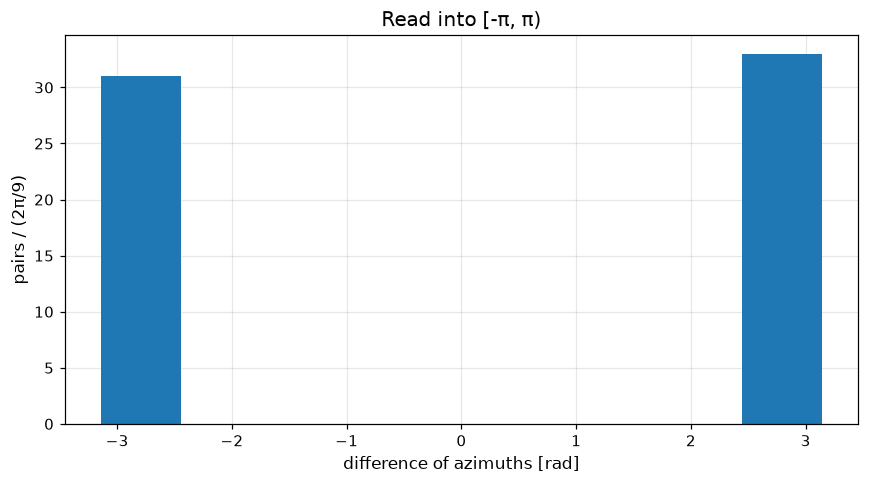

In [8]:
signed = wrap_to_signed_pi(difference)

plotting.plot_hist_1d(
    signed,
    xrange=(-np.pi, np.pi),
    xbins=9,
    xtitle="difference of azimuths [rad]",
    ytitle="pairs / (2π/9)",
    title="Read into [-π, π)",
)

One peak drawn as two halves, at either edge of the plot. Nothing is wrong with
the numbers — the range put its seam exactly where the answer is.

`[0, 2π)` puts its seam at 0 instead, and π in the middle:

<Axes: title={'center': 'Read into [0, 2π)'}, xlabel='difference of azimuths [rad]', ylabel='pairs / (2π/9)'>

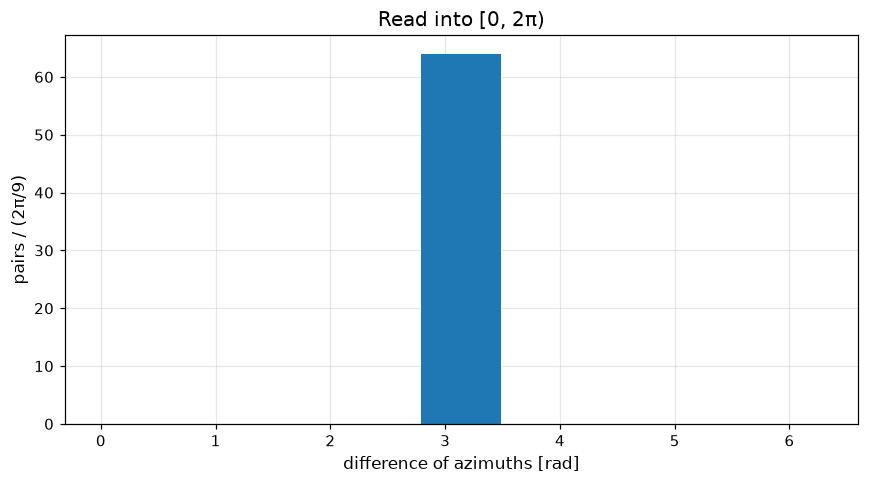

In [9]:
unsigned = wrap_to_two_pi(difference)

plotting.plot_hist_1d(
    unsigned,
    xrange=(0.0, 2.0 * np.pi),
    xbins=9,
    xtitle="difference of azimuths [rad]",
    ytitle="pairs / (2π/9)",
    title="Read into [0, 2π)",
)

In [10]:
np.abs(unsigned - np.pi).max()

np.float64(4.9315719508058464e-08)

One peak, at π, every pair within 5·10⁻⁸ rad of it. The rule of thumb: put the
seam of the range where the answers are not.

### A Direction And Its Reverse As One

The two gammas of a pair lie on one line through the source, the line of
response. A question about that line — not about which gamma went which way —
reads azimuths in `[0, π)`, where a direction and its reverse are one:

In [11]:
line_one = transform_to_angle_range(azimuth_one, 0.0, np.pi)
line_other = transform_to_angle_range(azimuth_other, 0.0, np.pi)

np.abs(line_other - line_one).max()

np.float64(4.931571939703616e-08)

Both gammas of every pair give the same azimuth of their line, to within
5·10⁻⁸ rad. The difference of π that the two previous sections read in two
ways is now no difference at all, because the range says that half a turn does
not count.

A seam is still a seam, though. Two directions exactly opposite always land on
the same value, but two that are only nearly opposite — as measured ones are —
can land on either side of it when their line lies close to the `x` axis: one
just above 0, the other just below π. Such a pair is close in angle and far
apart as numbers, so a comparison of lines over many events should measure the
difference in `[0, π)` too, rather than subtract plain numbers.

### Why The Ranges Are Half-Open

The range is `[angle_min, angle_max)`: the lower end belongs to it, the upper
end does not. An angle a hair below the lower end shows why that needs care.
Reduced by `numpy.mod` alone, it lands on the upper end — the one value the
range excludes:

In [12]:
just_below_zero = -1e-17

np.mod(just_below_zero, 2.0 * np.pi) == 2.0 * np.pi, wrap_to_two_pi([just_below_zero])

(np.True_, array([0.]))

`np.mod` answers 2π, which a histogram over `[0, 2π)` would count in its last
bin while the same direction, written as 0, goes in the first. The package
answers 0. Every angle it returns is in the range it was asked for, so an angle
never lands in the first bin or the last one depending on rounding.

A range that holds nothing has nowhere to read an angle into, and is refused:

In [13]:
try:
    transform_to_angle_range([1.0], np.pi, 0.0)
except ValueError as error:
    print(error)

An angle is read into a range that holds something: got [3.141592653589793, 0.0), which is empty.


## Summary

An angle is a direction up to whole turns, so the range it is read into is part
of the question: a full turn only changes how a direction is written, a
narrower range decides what counts as the same direction, and the seam of the
range should sit where the answers are not. `transform_to_angle_range`,
`wrap_to_two_pi` and `wrap_to_signed_pi` read angles into half-open ranges, so
every answer lies inside the range it was asked for.

## Bibliography

- [Vectors And Angles](https://opengate-gate-tree.readthedocs.io/en/latest/guide/vectors.html)
  — reading an angle into a range, and the spherical components the azimuth
  comes from
- [PositroniumSource Data](https://opengate-gate-tree.readthedocs.io/en/latest/guide/positronium.html)
  — what the values of `sourceType` and `gammaType` mean
- [Event Identifiers](https://opengate-gate-tree.readthedocs.io/en/latest/guide/events.html)
  — why an event is the pair `(runID, eventID)`

## Changelog

- v1: written.